<a href="https://colab.research.google.com/github/syifahumaira17/simuteh-2330511079/blob/main/notebook/B4_penapisan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%cd /content
!git clone https://github.com/syifahumaira17/simuteh-2330511079.git
%cd /content/simuteh-2330511079

/content
Cloning into 'simuteh-2330511079'...
remote: Enumerating objects: 250, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 250 (delta 4), reused 0 (delta 0), pack-reused 238 (from 1)
Receiving objects: 100% (250/250), 61.43 MiB | 30.55 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/simuteh-2330511079


In [ ]:
!pip install -q opencv-python-headless numpy matplotlib scikit-image pandas

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import os

from src.utils_cv import baca, tampil, statistik, kontras_bercak

print("Persiapan P4 berhasil!")
print("OpenCV:", cv2.__version__)

Persiapan P4 berhasil!
OpenCV: 5.0.0


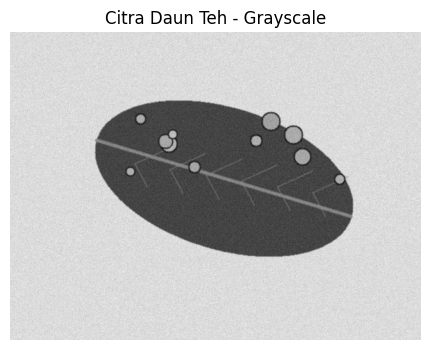

Ukuran citra: (480, 640)
Tipe data: uint8


In [ ]:
# Membaca citra daun teh
img = baca("data/sintetis/citra/teh_041.png")

# Mengubah citra BGR menjadi grayscale
bersih = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Menampilkan citra
plt.figure(figsize=(6, 4))
plt.imshow(bersih, cmap="gray")
plt.title("Citra Daun Teh - Grayscale")
plt.axis("off")
plt.show()

print("Ukuran citra:", bersih.shape)
print("Tipe data:", bersih.dtype)

In [ ]:
def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(
                pad[y:y+kh, x:x+kw] * k
            )

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img, k):
    return konvolusi(img, np.flip(k))


Kernel: Rerata
Selisih manual dan OpenCV: 0
Selisih konvolusi sejati dan OpenCV: 0
Waktu manual: 1.4649 detik
Waktu OpenCV: 0.0306 detik


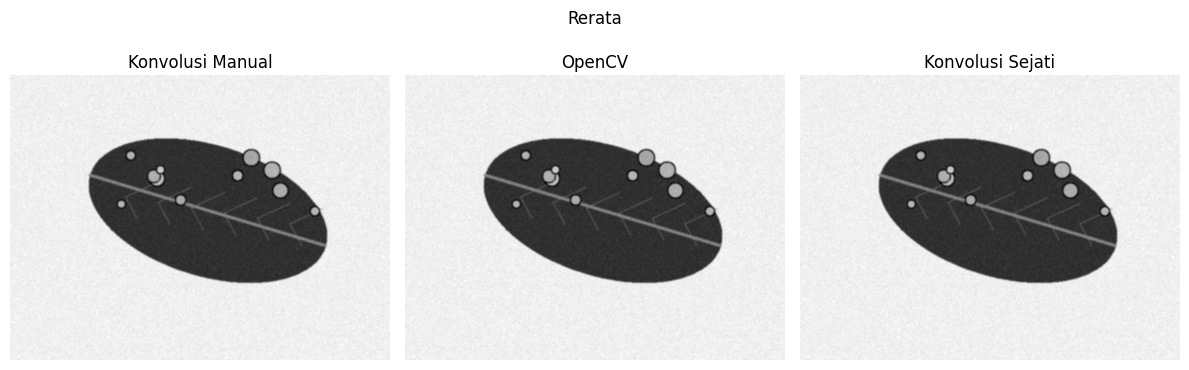


Kernel: Asimetris
Selisih manual dan OpenCV: 0
Selisih konvolusi sejati dan OpenCV: 255
Waktu manual: 1.4814 detik
Waktu OpenCV: 0.0003 detik


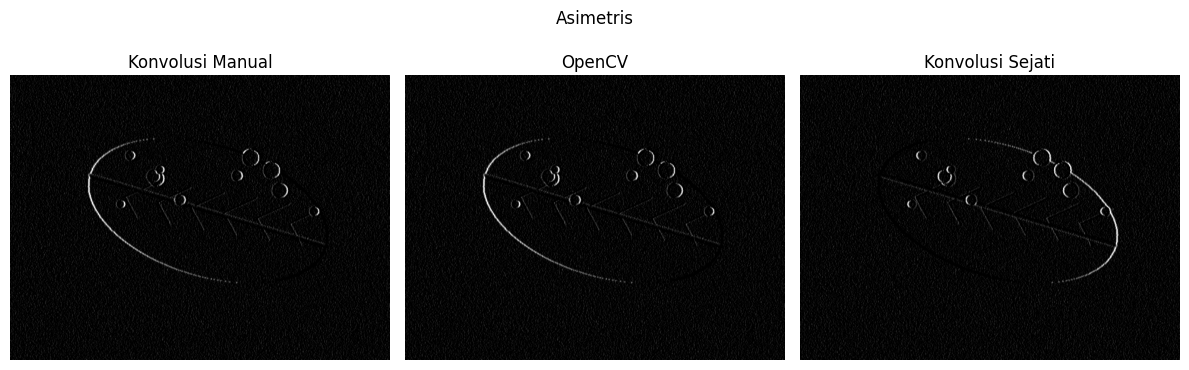

In [ ]:
kernel_rerata = np.ones((3, 3), dtype=float) / 9

kernel_asimetris = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
], dtype=float)

daftar_kernel = {
    "Rerata": kernel_rerata,
    "Asimetris": kernel_asimetris
}

for nama, kernel in daftar_kernel.items():

    # Konvolusi manual
    mulai = time.perf_counter()
    hasil_manual = konvolusi(bersih, kernel)
    waktu_manual = time.perf_counter() - mulai

    # OpenCV
    mulai = time.perf_counter()
    hasil_cv = cv2.filter2D(
        bersih,
        -1,
        kernel,
        borderType=cv2.BORDER_REPLICATE
    )
    waktu_cv = time.perf_counter() - mulai

    # Konvolusi sejati
    hasil_sejati = konvolusi_sejati(bersih, kernel)

    print("\nKernel:", nama)
    print("Selisih manual dan OpenCV:",
          np.abs(hasil_manual.astype(int) -
                 hasil_cv.astype(int)).max())
    print("Selisih konvolusi sejati dan OpenCV:",
          np.abs(hasil_sejati.astype(int) -
                 hasil_cv.astype(int)).max())
    print("Waktu manual:", round(waktu_manual, 4), "detik")
    print("Waktu OpenCV:", round(waktu_cv, 4), "detik")

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(hasil_manual, cmap="gray")
    plt.title("Konvolusi Manual")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(hasil_cv, cmap="gray")
    plt.title("OpenCV")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(hasil_sejati, cmap="gray")
    plt.title("Konvolusi Sejati")
    plt.axis("off")

    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

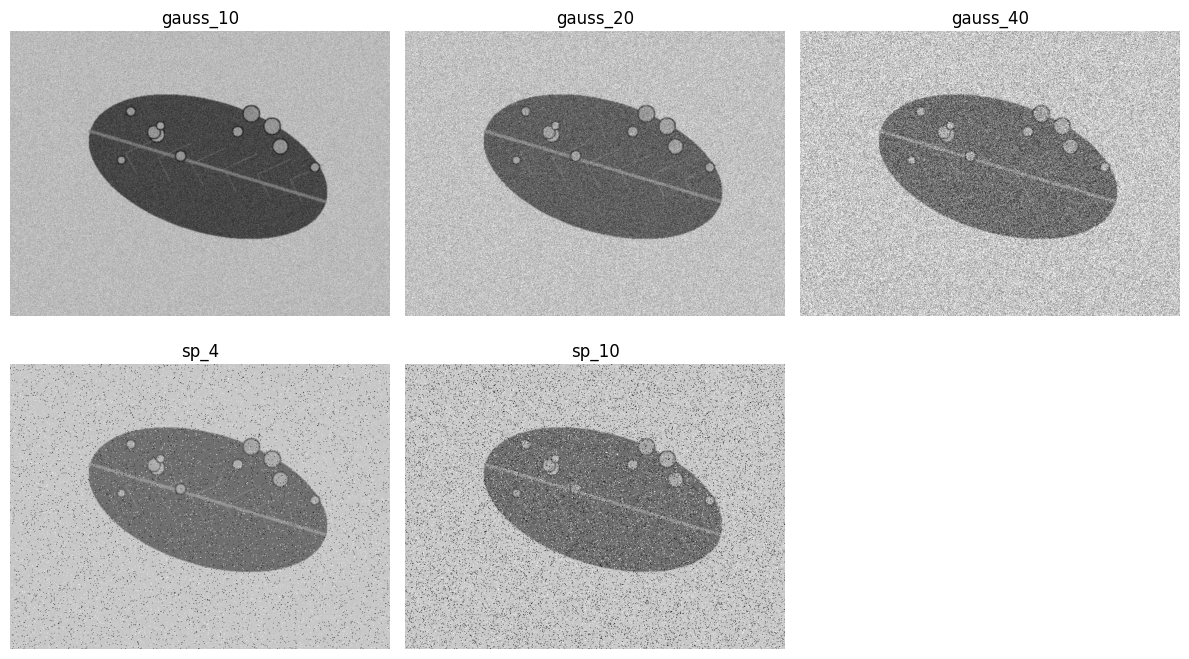

In [ ]:
# Membuat beberapa jenis derau
rng = np.random.default_rng(1079)

derau = {}

# Gaussian noise
for sd in [10, 20, 40]:
    noise = rng.normal(0, sd, bersih.shape)
    hasil = np.clip(bersih.astype(float) + noise, 0, 255)
    derau[f"gauss_{sd}"] = hasil.astype(np.uint8)

# Salt and pepper noise
for persen in [0.04, 0.10]:
    hasil = bersih.copy()
    jumlah = int(persen * bersih.size)

    indeks = rng.choice(bersih.size, jumlah, replace=False)
    setengah = jumlah // 2

    hasil.flat[indeks[:setengah]] = 0
    hasil.flat[indeks[setengah:]] = 255

    derau[f"sp_{int(persen*100)}"] = hasil

# Menampilkan citra
plt.figure(figsize=(12, 7))

for i, (nama, citra) in enumerate(derau.items(), 1):
    plt.subplot(2, 3, i)
    plt.imshow(citra, cmap="gray")
    plt.title(nama)
    plt.axis("off")

plt.tight_layout()
plt.show()

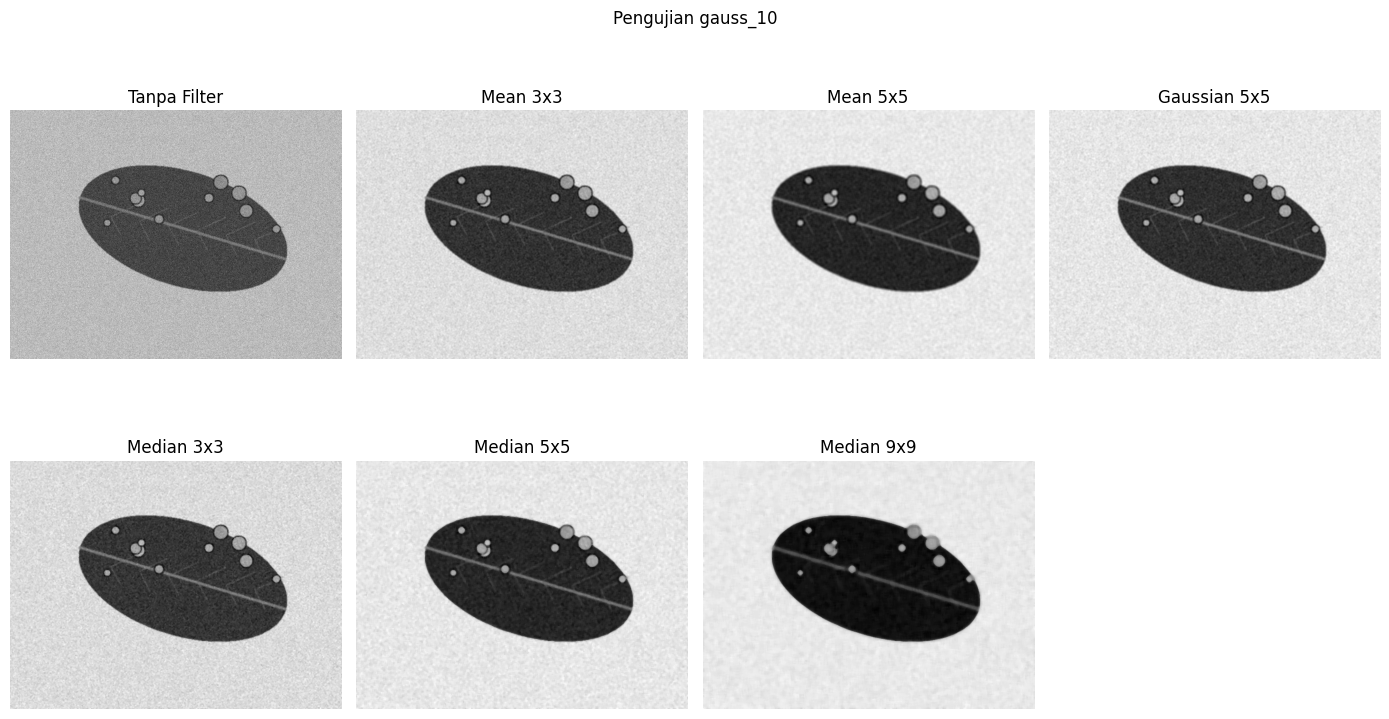

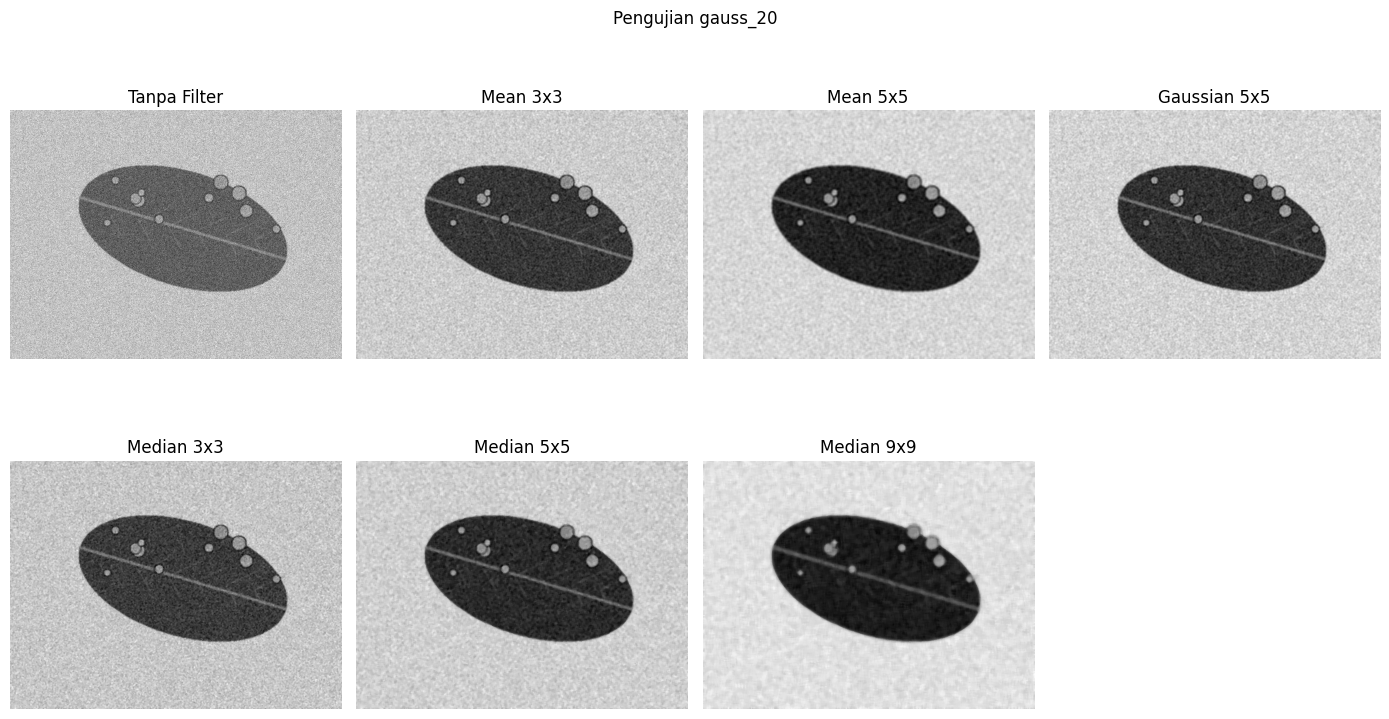

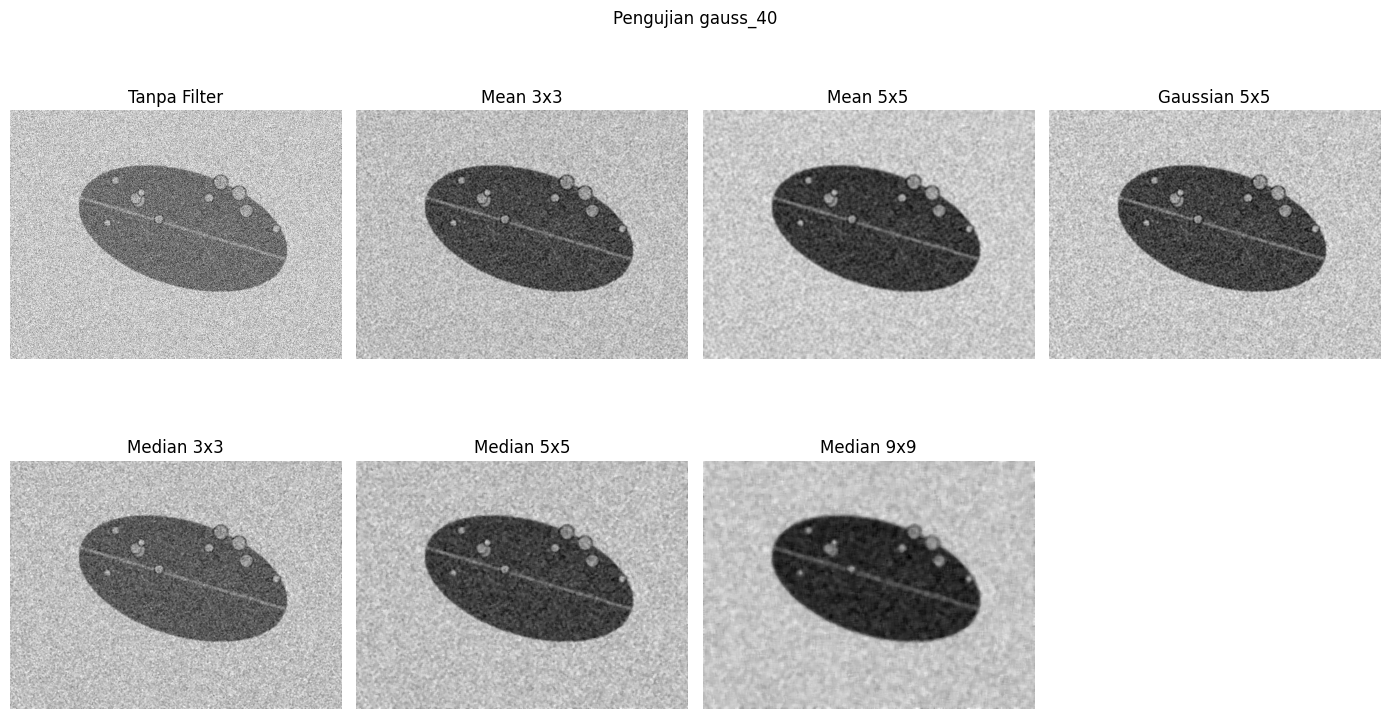

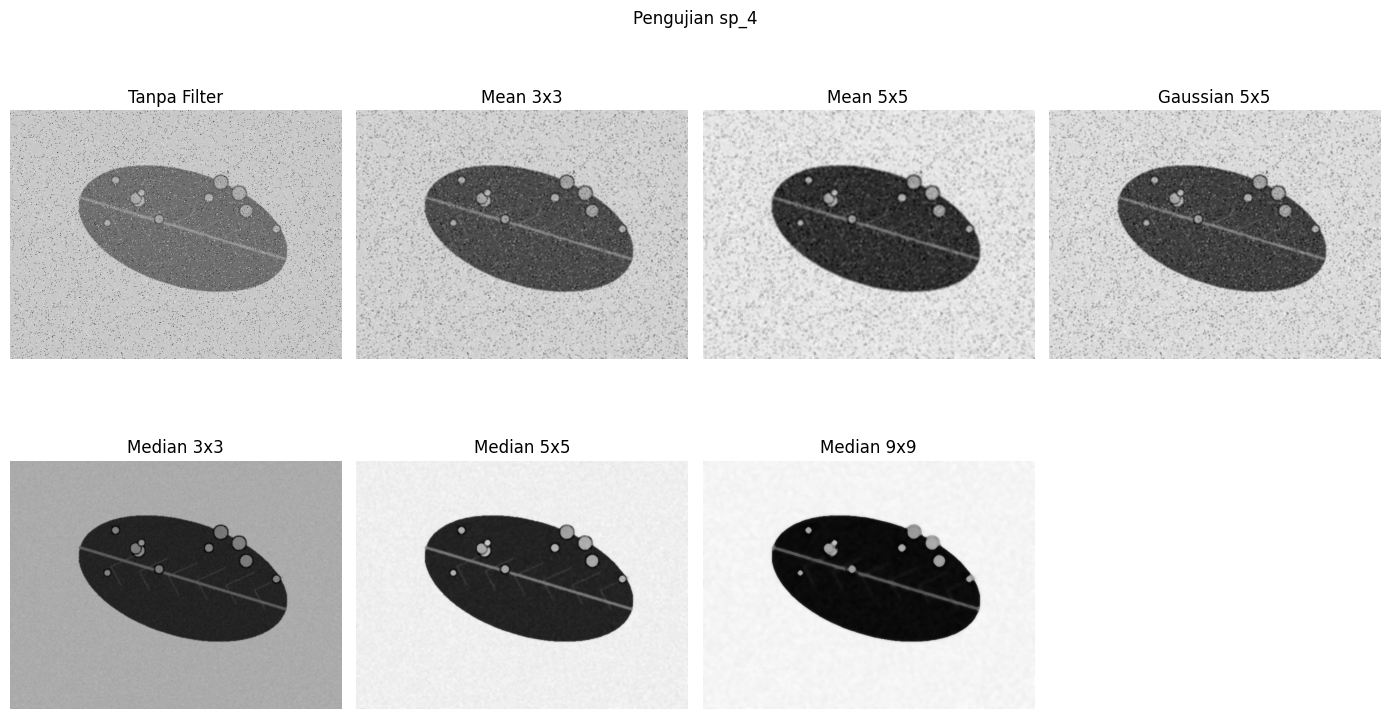

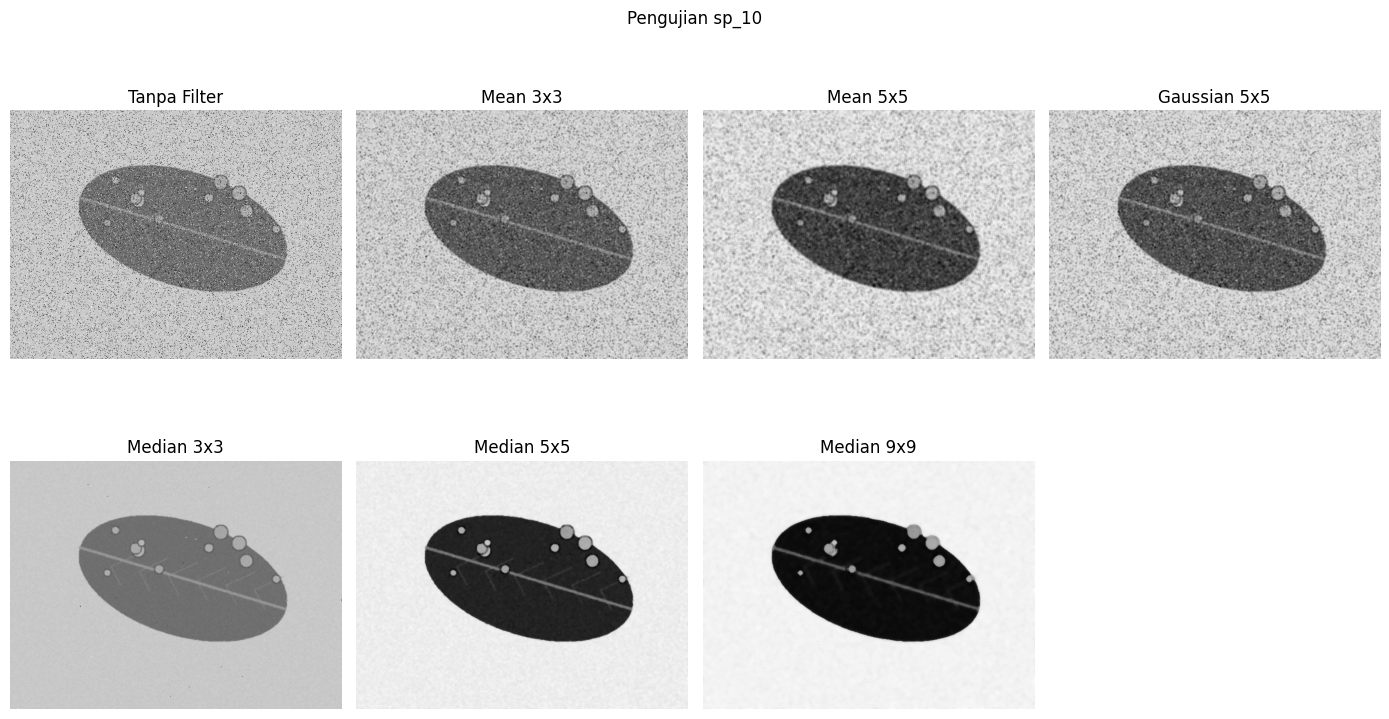

In [ ]:
# Membuat daftar filter
filter_list = {
    "Tanpa Filter": lambda x: x,
    "Mean 3x3": lambda x: cv2.blur(x, (3, 3)),
    "Mean 5x5": lambda x: cv2.blur(x, (5, 5)),
    "Gaussian 5x5": lambda x: cv2.GaussianBlur(x, (5, 5), 0),
    "Median 3x3": lambda x: cv2.medianBlur(x, 3),
    "Median 5x5": lambda x: cv2.medianBlur(x, 5),
    "Median 9x9": lambda x: cv2.medianBlur(x, 9)
}

# Menampilkan hasil filter pada setiap jenis derau
for nama_derau, citra_derau in derau.items():

    plt.figure(figsize=(14, 8))

    for i, (nama_filter, fungsi) in enumerate(filter_list.items(), 1):
        hasil_filter = fungsi(citra_derau)

        plt.subplot(2, 4, i)
        plt.imshow(hasil_filter, cmap="gray")
        plt.title(nama_filter)
        plt.axis("off")

    plt.suptitle("Pengujian " + nama_derau)
    plt.tight_layout()
    plt.show()

In [ ]:
import inspect

print(inspect.signature(kontras_bercak))
print(inspect.getsource(kontras_bercak))

(kanal, mask_daun, mask_bercak)
def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)



In [ ]:
# Memuat mask daun dan mask bercak
mask_daun = cv2.imread(
    "data/sintetis/mask_daun/teh_041.png",
    cv2.IMREAD_GRAYSCALE
)

mask_bercak = cv2.imread(
    "data/sintetis/mask_bercak/teh_041.png",
    cv2.IMREAD_GRAYSCALE
)

print("Ukuran mask daun:", mask_daun.shape)
print("Ukuran mask bercak:", mask_bercak.shape)
print("Jumlah piksel daun:", np.sum(mask_daun > 0))
print("Jumlah piksel bercak:", np.sum(mask_bercak > 0))

Ukuran mask daun: (480, 640)
Ukuran mask bercak: (480, 640)
Jumlah piksel daun: 71933
Jumlah piksel bercak: 3652


In [ ]:
# Fungsi menghitung PSNR
def hitung_psnr(asli, hasil):
    return cv2.PSNR(asli, hasil)


# Menyimpan hasil evaluasi
hasil_evaluasi = []

for nama_derau, citra_derau in derau.items():

    for nama_filter, fungsi in filter_list.items():

        # Mengukur waktu pemrosesan
        mulai = time.perf_counter()
        hasil_filter = fungsi(citra_derau)
        waktu = time.perf_counter() - mulai

        # Menghitung PSNR terhadap citra asli
        psnr = hitung_psnr(bersih, hasil_filter)

        # Menghitung Kontras Bercak (KB)
        kb = kontras_bercak(
            hasil_filter,
            mask_daun,
            mask_bercak
        )

        hasil_evaluasi.append({
            "Jenis Derau": nama_derau,
            "Filter": nama_filter,
            "PSNR (dB)": psnr,
            "Waktu (detik)": waktu,
            "KB": kb
        })


# Membuat tabel hasil
df_evaluasi = pd.DataFrame(hasil_evaluasi)

df_evaluasi = df_evaluasi.round({
    "PSNR (dB)": 2,
    "Waktu (detik)": 5,
    "KB": 4
})

display(df_evaluasi)

# Menyimpan tabel ke folder hasil
df_evaluasi.to_csv(
    "hasil/b4_tabel_penapis.csv",
    index=False
)

print("Tabel berhasil disimpan!")

,Jenis Derau,Filter,PSNR (dB),Waktu (detik),KB
0,gauss_10,Tanpa Filter,28.11,0.00001,2.4296
1,gauss_10,Mean 3x3,33.25,0.00105,4.0581
2,gauss_10,Mean 5x5,33.31,0.00027,4.3321
3,gauss_10,Gaussian 5x5,33.96,0.00058,4.2306
4,gauss_10,Median 3x3,32.46,0.00009,3.9579
5,gauss_10,Median 5x5,33.45,0.00063,4.6431
6,gauss_10,Median 9x9,33.24,0.01483,5.2559
7,gauss_20,Tanpa Filter,22.14,0.00000,1.4416
8,gauss_20,Mean 3x3,30.09,0.00012,3.2470
9,gauss_20,Mean 5x5,31.89,0.00013,3.8960


Tabel berhasil disimpan!


In [ ]:
# Daftar ukuran kernel median
ukuran_kernel = [1, 3, 5, 9, 15]

# Menyiapkan daftar citra bercak ringan
daftar_citra = []

for i in range(21, 41):
    nama = f"teh_{i:03d}.png"

    img = baca(f"data/sintetis/citra/{nama}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    mask_daun_i = cv2.imread(
        f"data/sintetis/mask_daun/{nama}",
        cv2.IMREAD_GRAYSCALE
    )

    mask_bercak_i = cv2.imread(
        f"data/sintetis/mask_bercak/{nama}",
        cv2.IMREAD_GRAYSCALE
    )

    daftar_citra.append(
        (nama, gray, mask_daun_i, mask_bercak_i)
    )

print("Jumlah citra:", len(daftar_citra))
print("Ukuran kernel:", ukuran_kernel)
print("Persiapan P4.4 berhasil!")

Jumlah citra: 20
Ukuran kernel: [1, 3, 5, 9, 15]
Persiapan P4.4 berhasil!


In [ ]:
hasil_median = []

for nama, gray, md, mb in daftar_citra:

    for k in ukuran_kernel:

        # Menerapkan filter median
        hasil = cv2.medianBlur(gray, k)

        # Menghitung perubahan intensitas rata-rata
        dI = np.mean(
            np.abs(
                hasil.astype(np.float32) -
                gray.astype(np.float32)
            )
        )

        # Menghitung Kontras Bercak
        kb = kontras_bercak(hasil, md, mb)

        hasil_median.append({
            "Citra": nama,
            "Kernel": k,
            "dI": dI,
            "KB": kb
        })

# Membuat tabel hasil
df_median = pd.DataFrame(hasil_median)

display(df_median.round(4))

# Menyimpan hasil ke CSV
df_median.to_csv(
    "hasil/b4_eksperimen_median.csv",
    index=False
)

print("Pengujian median berhasil!")
print("Jumlah pengujian:", len(df_median))

,Citra,Kernel,dI,KB
0,teh_021.png,1,0.0000,2.7742
1,teh_021.png,3,5.2054,3.8820
2,teh_021.png,5,5.6102,4.1614
3,teh_021.png,9,5.8389,4.1375
4,teh_021.png,15,6.0500,2.4764
...,...,...,...,...
95,teh_040.png,1,0.0000,2.0297
96,teh_040.png,3,5.7245,2.2547
97,teh_040.png,5,6.1360,2.2156
98,teh_040.png,9,6.3425,1.8164


Pengujian median berhasil!
Jumlah pengujian: 100


,Kernel,dI,KB
0,1,0.0000,2.2504
1,3,4.6629,3.2141
2,5,5.0104,3.4224
3,9,5.1992,3.0673
4,15,5.3447,1.8515


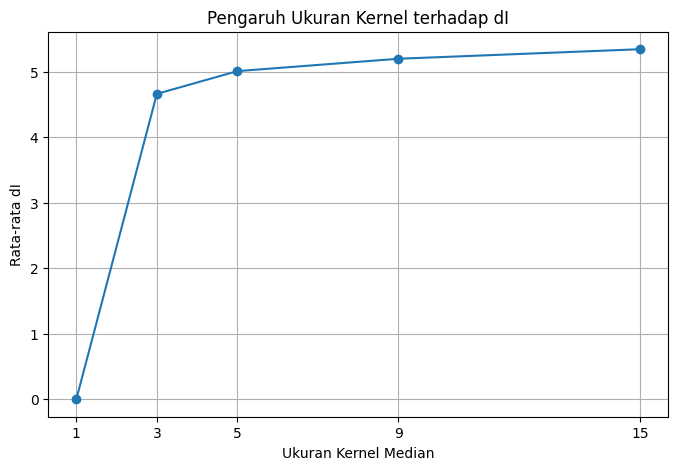

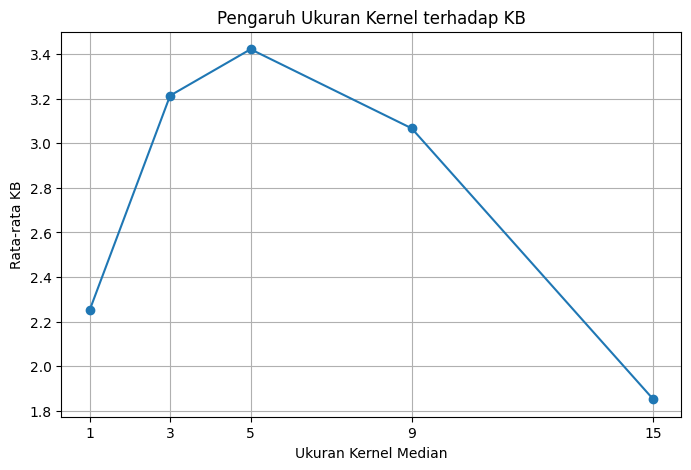

In [ ]:
# Menghitung rata-rata dI dan KB untuk setiap kernel
ringkasan_median = (
    df_median.groupby("Kernel")[["dI", "KB"]]
    .mean()
    .reset_index()
)

display(ringkasan_median.round(4))

# Grafik perubahan intensitas (dI)
plt.figure(figsize=(8, 5))
plt.plot(
    ringkasan_median["Kernel"],
    ringkasan_median["dI"],
    marker="o"
)
plt.title("Pengaruh Ukuran Kernel terhadap dI")
plt.xlabel("Ukuran Kernel Median")
plt.ylabel("Rata-rata dI")
plt.xticks(ukuran_kernel)
plt.grid(True)
plt.savefig("hasil/b4_grafik_di_median.png")
plt.show()

# Grafik Kontras Bercak (KB)
plt.figure(figsize=(8, 5))
plt.plot(
    ringkasan_median["Kernel"],
    ringkasan_median["KB"],
    marker="o"
)
plt.title("Pengaruh Ukuran Kernel terhadap KB")
plt.xlabel("Ukuran Kernel Median")
plt.ylabel("Rata-rata KB")
plt.xticks(ukuran_kernel)
plt.grid(True)
plt.savefig("hasil/b4_grafik_kb_median.png")
plt.show()

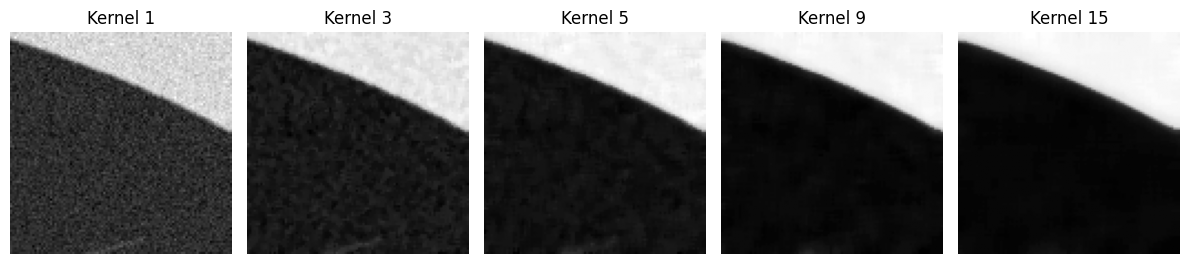

In [ ]:
nama = "teh_021.png"

img = baca(f"data/sintetis/citra/{nama}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Ambil potongan bagian tengah citra
y, x = 200, 300
crop = gray[y-50:y+50, x-50:x+50]

plt.figure(figsize=(12, 3))

for i, k in enumerate(ukuran_kernel):
    hasil = cv2.medianBlur(crop, k)

    plt.subplot(1, 5, i+1)
    plt.imshow(hasil, cmap="gray")
    plt.title(f"Kernel {k}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil/b4_crop_median.png")
plt.show()

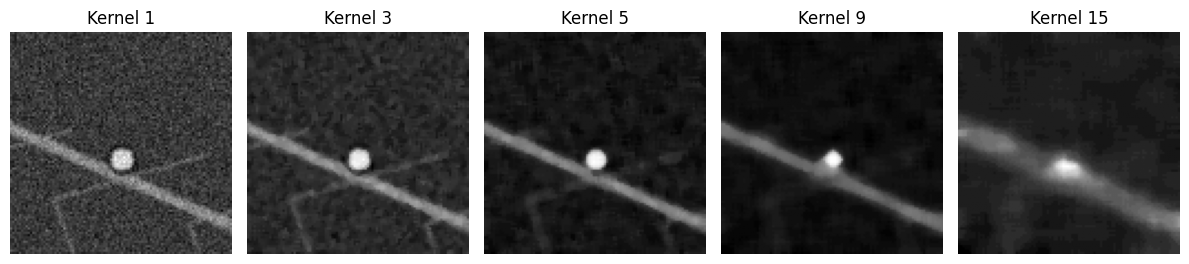

In [ ]:
nama = "teh_021.png"

gray = cv2.cvtColor(
    baca(f"data/sintetis/citra/{nama}"),
    cv2.COLOR_BGR2GRAY
)

mask_bercak = cv2.imread(
    f"data/sintetis/mask_bercak/{nama}",
    cv2.IMREAD_GRAYSCALE
)

# Cari lokasi bercak
y, x = np.argwhere(mask_bercak > 0)[0]

# Ambil potongan di sekitar bercak
crop = gray[
    max(0, y-50):y+50,
    max(0, x-50):x+50
]

plt.figure(figsize=(12, 3))

for i, k in enumerate(ukuran_kernel):
    hasil = cv2.medianBlur(crop, k)

    plt.subplot(1, 5, i+1)
    plt.imshow(hasil, cmap="gray")
    plt.title(f"Kernel {k}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil/b4_crop_bercak_median.png")
plt.show()

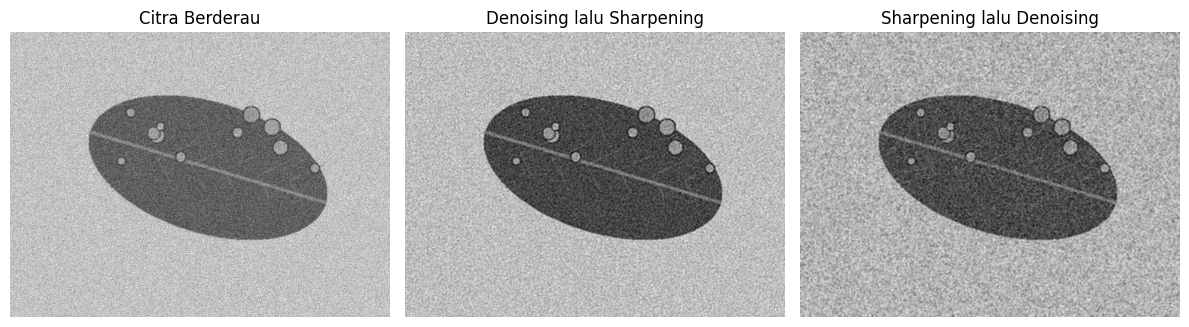

In [ ]:
# Citra dengan Gaussian noise
img_noisy = derau["gauss_20"]

# Kernel untuk sharpening
kernel_sharp = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

# Urutan 1: Denoising lalu sharpening
denoise_dulu = cv2.GaussianBlur(img_noisy, (5, 5), 0)
hasil_urutan1 = cv2.filter2D(
    denoise_dulu, -1, kernel_sharp
)

# Urutan 2: Sharpening lalu denoising
sharp_dulu = cv2.filter2D(
    img_noisy, -1, kernel_sharp
)
hasil_urutan2 = cv2.GaussianBlur(
    sharp_dulu, (5, 5), 0
)

# Perbandingan hasil
plt.figure(figsize=(12, 4))

gambar = [
    img_noisy,
    hasil_urutan1,
    hasil_urutan2
]

judul = [
    "Citra Berderau",
    "Denoising lalu Sharpening",
    "Sharpening lalu Denoising"
]

for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(gambar[i], cmap="gray")
    plt.title(judul[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil/b4_urutan_denoise_sharpen.png")
plt.show()

In [ ]:
# Menghitung PSNR terhadap citra asli
psnr_urutan1 = cv2.PSNR(bersih, hasil_urutan1)
psnr_urutan2 = cv2.PSNR(bersih, hasil_urutan2)

# Area latar belakang (di luar daun)
mask_background = (mask_daun == 0)

# Menghitung standar deviasi pada latar belakang
std_urutan1 = np.std(
    hasil_urutan1[mask_background]
)

std_urutan2 = np.std(
    hasil_urutan2[mask_background]
)

# Menampilkan tabel perbandingan
df_urutan = pd.DataFrame({
    "Urutan": [
        "Denoising lalu Sharpening",
        "Sharpening lalu Denoising"
    ],
    "PSNR (dB)": [
        psnr_urutan1,
        psnr_urutan2
    ],
    "Std Latar Belakang": [
        std_urutan1,
        std_urutan2
    ]
})

display(df_urutan.round(4))

print("Pengujian P4.5 berhasil!")

,Urutan,PSNR (dB),Std Latar Belakang
0,Denoising lalu Sharpening,27.1372,11.4472
1,Sharpening lalu Denoising,21.5646,11.3523


Pengujian P4.5 berhasil!


In [ ]:
# Ukuran kernel
ukuran_kernel = 5
perkalian_per_piksel = ukuran_kernel * ukuran_kernel

# Resolusi citra
resolusi_asli = (4000, 3000)
resolusi_proses = (640, 480)

# Menghitung jumlah operasi perkalian
operasi_asli = (
    resolusi_asli[0] *
    resolusi_asli[1] *
    perkalian_per_piksel
)

operasi_proses = (
    resolusi_proses[0] *
    resolusi_proses[1] *
    perkalian_per_piksel
)

print("Kernel:", ukuran_kernel, "x", ukuran_kernel)
print("Perkalian per piksel:", perkalian_per_piksel)

print("\nResolusi asli 4000 x 3000:")
print(f"Jumlah perkalian: {operasi_asli:,}")

print("\nResolusi proses 640 x 480:")
print(f"Jumlah perkalian: {operasi_proses:,}")

print("\nPerbandingan beban komputasi:")
print(f"{operasi_asli / operasi_proses:.2f} kali")

Kernel: 5 x 5
Perkalian per piksel: 25

Resolusi asli 4000 x 3000:
Jumlah perkalian: 300,000,000

Resolusi proses 640 x 480:
Jumlah perkalian: 7,680,000

Perbandingan beban komputasi:
39.06 kali


P4.7 – Privasi Citra

Foto yang memuat wajah petani termasuk data pribadi yang perlu dilindungi. Penggunaan blur ringan belum tentu aman karena sebagian ciri wajah masih dapat dikenali atau dipulihkan melalui teknik tertentu. Prosedur yang lebih aman adalah menghindari pengambilan wajah sejak awal, memotong bagian gambar yang tidak diperlukan, atau menutup seluruh area wajah secara permanen sebelum citra disimpan atau dibagikan. Pengambilan dan penggunaan foto juga harus memperhatikan persetujuan pihak yang bersangkutan.

In [9]:
import os

print("Lokasi kerja:", os.getcwd())
print("Isi folder:", os.listdir())

Lokasi kerja: /content
Isi folder: ['.config', 'simuteh-2330511079', 'sample_data']


In [10]:
import os

for root, dirs, files in os.walk('/content/simuteh-2330511079'):
    if 'label.csv' in files:
        print("File ditemukan:", os.path.join(root, 'label.csv'))

File ditemukan: /content/simuteh-2330511079/data/sintetis/label.csv


In [13]:

# P4.6 - Pengujian PSNR pada 12 Citra Kondisi Normal

# 1. Import library
import pandas as pd
import numpy as np
import cv2
import os

# 2. Menentukan lokasi folder repository
BASE_DIR = "/content/simuteh-2330511079"

# 3. Membaca data label
df_label = pd.read_csv(
    os.path.join(BASE_DIR, "data/sintetis/label.csv")
)

# 4. Memilih 12 citra dengan kondisi cahaya normal
citra_normal = (
    df_label[df_label["kondisi_cahaya"] == "normal"]
    .sort_values("nama_file")
)

print("Jumlah citra kondisi normal:", len(citra_normal))

# 5. Memastikan jumlah citra sesuai ketentuan
assert len(citra_normal) == 12, "Jumlah citra normal bukan 12!"

# 6. Menyiapkan generator derau
rng = np.random.default_rng(1079)

# 7. Menyimpan hasil pengujian
hasil_psnr = []

for nama in citra_normal["nama_file"]:

    # Membaca citra asli
    path_citra = os.path.join(
        BASE_DIR, "data/sintetis/citra", nama
    )

    img = cv2.imread(path_citra)

    # Memastikan citra berhasil dibaca
    if img is None:
        raise FileNotFoundError(
            f"Citra tidak ditemukan: {path_citra}"
        )

    # Mengubah citra menjadi grayscale
    citra_asli = cv2.cvtColor(
        img, cv2.COLOR_BGR2GRAY
    )

    # Membuat Gaussian Noise (standar deviasi 20)
    noise = rng.normal(0, 20, citra_asli.shape)

    citra_derau = np.clip(
        citra_asli.astype(float) + noise,
        0, 255
    ).astype(np.uint8)

    # Menerapkan filter Median 9x9
    hasil_filter = cv2.medianBlur(citra_derau, 9)

    # Menghitung PSNR sebelum dan sesudah penapisan
    psnr_sebelum = cv2.PSNR(
        citra_asli, citra_derau
    )

    psnr_sesudah = cv2.PSNR(
        citra_asli, hasil_filter
    )

    # Menyimpan hasil pengujian
    hasil_psnr.append({
        "Nama Citra": nama,
        "PSNR Sebelum (dB)": psnr_sebelum,
        "PSNR Sesudah (dB)": psnr_sesudah
    })

# 8. Membuat tabel hasil pengujian
df_psnr_normal = pd.DataFrame(hasil_psnr)

print("\nTabel Hasil Pengujian PSNR:")
display(df_psnr_normal.round(2))

# 9. Membuat folder hasil jika belum tersedia
folder_hasil = os.path.join(BASE_DIR, "hasil")
os.makedirs(folder_hasil, exist_ok=True)

# 10. Menyimpan tabel ke CSV
path_hasil = os.path.join(
    folder_hasil,
    "b4_psnr_12_citra_normal.csv"
)

df_psnr_normal.to_csv(
    path_hasil,
    index=False
)

# 11. Menampilkan informasi pengujian
print("\nPengujian PSNR 12 citra normal berhasil!")
print("Jumlah citra diuji:", len(df_psnr_normal))
print("Hasil disimpan di:", path_hasil)


Jumlah citra kondisi normal: 12

Tabel Hasil Pengujian PSNR:


,Nama Citra,PSNR Sebelum (dB),PSNR Sesudah (dB)
0,teh_001.png,22.14,28.00
1,teh_006.png,22.13,31.98
2,teh_011.png,22.11,29.64
3,teh_016.png,22.11,32.33
4,teh_021.png,22.15,29.82
5,teh_026.png,22.12,31.35
6,teh_031.png,22.12,31.09
7,teh_036.png,22.10,29.42
8,teh_041.png,22.13,32.10
9,teh_046.png,22.10,28.06



Pengujian PSNR 12 citra normal berhasil!
Jumlah citra diuji: 12
Hasil disimpan di: /content/simuteh-2330511079/hasil/b4_psnr_12_citra_normal.csv
